In [3]:
# imports
import matplotlib.pyplot as plt
import numpy
import pandas as pd

In [4]:
df = pd.read_csv(r"C:\Users\Client\Documents\Calibration_ISF\Data\2026-10-09\span_conditionneur.csv")

In [5]:
# get index of max value
maximum = df["F"].idxmax()

# Linear regression from 0 to maximum
uptrend = df.loc[0:maximum]
downtrend = df.loc[maximum:]

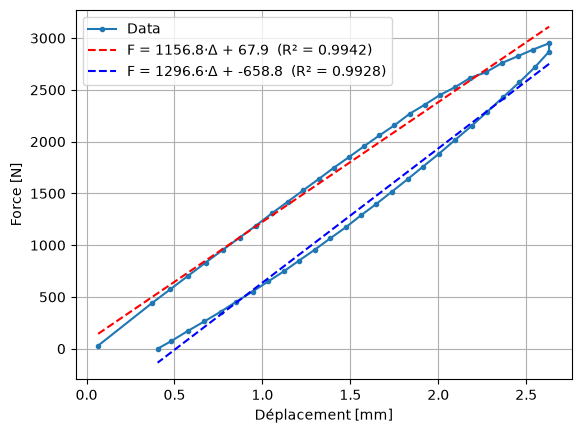

In [6]:
x_uptrend = -uptrend["Delta"]
y_uptrend = uptrend["F"]
slope, intercept = numpy.polyfit(x_uptrend, y_uptrend, 1)
r2 = numpy.corrcoef(x_uptrend, y_uptrend)[0, 1] ** 2

x_downtrend = -downtrend["Delta"]
y_downtrend = downtrend["F"]
slope2, intercept2 = numpy.polyfit(x_downtrend, y_downtrend, 1)
r2_2 = numpy.corrcoef(x_downtrend, y_downtrend)[0, 1] ** 2

plt.plot(-df["Delta"], df["F"], "o-", ms=3, label="Data")
plt.plot(x_uptrend, slope * x_uptrend + intercept, "r--", label=f"F = {slope:.1f}·Δ + {intercept:.1f}  (R² = {r2:.4f})")
plt.plot(x_downtrend, slope2 * x_downtrend + intercept2, "b--", label=f"F = {slope2:.1f}·Δ + {intercept2:.1f}  (R² = {r2_2:.4f})")
plt.xlabel("Déplacement [mm]")
plt.ylabel("Force [N]")
plt.legend()
plt.grid(True)
plt.show()

# Pour la prochaine calibration
- Faire 3 allers-retours de chargement -déchargement avant de prendre les mesures.
- Attendre entre 5 et 10 secondes entre chaque palier.
- Viser 8 paliers.